# Paso 4 – Transformación de los datos y evaluación de PCA

**Proyecto:** seguimiento de residentes del Puericultorio Pérez Araníbar.

El Paso 3 dejó `Dataset_unificado_3.xlsx` con un registro por residente y mes. Para agrupar residentes (clustering) se necesita **un solo registro por NNA**, por lo que este cuaderno:

1. Toma la **ficha nominal del último periodo (2026-07)** como descripción actual del residente.
2. Resume su **historial mensual (enero 2025 – julio 2026)** y sus **evaluaciones nutricionales** en variables derivadas que describen *evolución, persistencia, frecuencia y cambios*.
3. Guarda la matriz analítica en `Dataset_paso4_variables.xlsx`.
4. Evalúa si se puede aplicar **PCA** (correlaciones, estandarización, Bartlett, KMO, componentes, varianza explicada, cargas y puntajes).


# 1. Lectura del consolidado 3

In [ ]:
from pathlib import Path
import re
import unicodedata
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', 220)

# Raíz del proyecto: este cuaderno se guarda en la carpeta Notebooks
BASE = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
RUTA_ENTRADA = BASE / 'Resultados' / 'Consolidado' / 'Dataset_unificado_3.xlsx'
RUTA_SALIDA = BASE / 'Resultados' / 'Consolidado' / 'Dataset_paso4_variables.xlsx'
RUTA_PCA = BASE / 'Resultados' / 'Consolidado' / 'Dataset_paso4_pca.xlsx'
RUTA_EVID = BASE / 'Resultados' / 'Paso4_evidencias'
RUTA_EVID.mkdir(parents=True, exist_ok=True)

PERIODO_CORTE = '2026-07'
FECHA_CORTE = pd.Timestamp('2026-07-31')

df = pd.read_excel(RUTA_ENTRADA)
print(f'Registros: {df.shape[0]:,} | Columnas: {df.shape[1]} | Residentes: {df["id_persona"].nunique()}')
print('Periodos:', df['periodo'].min(), 'a', df['periodo'].max())
df.groupby('periodo')['id_persona'].nunique().to_frame('residentes').T

Registros: 2,459 | Columnas: 43 | Residentes: 145
Periodos: 2025-01 a 2026-08


periodo,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
residentes,131,130,129,129,128,129,131,130,130,132,132,129,129,126,123,123,122,122,122,32


**Comentario 1:** el consolidado tiene 2 459 registros de 145 residentes, de enero de 2025 a **agosto de 2026**. El número de residentes por mes baja de 131 a 122: la población solo disminuye por egresos, como indicó la institución en el Paso 1. Agosto aparece con solo 32 residentes porque corresponde únicamente a evaluaciones nutricionales de los hogares Matogroso y no tiene ficha nominal.

# 2. Definición de la población y del corte

In [ ]:
COL_NOM = [c for c in df.columns if c.startswith('nom_')]
df['tiene_ficha'] = df[COL_NOM].notna().any(axis=1)

# Registros que solo tienen nutrición (sin ficha nominal del mes)
sin_ficha = df[~df['tiene_ficha']]
print('Registros sin ficha nominal por periodo:', sin_ficha.groupby('periodo').size().to_dict())

# Corte: se descartan los periodos posteriores a julio de 2026
df = df[df['periodo'] <= PERIODO_CORTE].copy()

# Población: residentes con ficha nominal en el periodo de corte
ids_poblacion = sorted(df.loc[(df['periodo'] == PERIODO_CORTE) & df['tiene_ficha'], 'id_persona'].unique())
df = df[df['id_persona'].isin(ids_poblacion)].sort_values(['id_persona', 'periodo']).reset_index(drop=True)

fichas = df[df['tiene_ficha']].copy()          # historial de la ficha nominal
ultima = fichas[fichas['periodo'] == PERIODO_CORTE].set_index('id_persona')   # ficha del último periodo
evals = df[df['nut_id_evaluacion'].notna()].copy()    # evaluaciones nutricionales hasta julio

print(f'\nPoblación de análisis: {len(ids_poblacion)} residentes')
print(f'Fichas del historial: {len(fichas):,} | Evaluaciones nutricionales: {len(evals)}')
meses = fichas.groupby('id_persona').size()
print('Meses de ficha por residente:', meses.value_counts().sort_index().to_dict())

Registros sin ficha nominal por periodo: {'2026-01': 4, '2026-02': 1, '2026-08': 32}

Población de análisis: 122 residentes
Fichas del historial: 2,279 | Evaluaciones nutricionales: 304
Meses de ficha por residente: {10: 1, 11: 1, 15: 1, 16: 4, 17: 2, 18: 2, 19: 111}


**Comentario 2:** la población de análisis son los **122 residentes con ficha nominal en julio de 2026**. Es menor a los 134 del corte original porque en el Paso 3 se excluyeron los códigos de identidad inconsistente (8) y los de cronología incompatible (4). Los registros de agosto se descartan, ya que no tienen ficha y el alcance del proyecto es la información hasta julio. Las 5 evaluaciones nutricionales de enero y febrero que no tienen ficha ese mes se conservan, pero solo para las variables nutricionales. Del historial, 111 de los 122 residentes tienen los 19 meses completos y el resto ingresó durante 2025 o tiene meses sin registro, por eso las proporciones se calculan sobre los **meses realmente observados** de cada residente y no sobre 19.

# 3. Codificación de los textos para derivar variables

In [ ]:
def norm(x):
    """Minúsculas, sin tildes y con espacios simples."""
    if pd.isna(x):
        return np.nan
    t = unicodedata.normalize('NFKD', str(x)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'\s+', ' ', t).strip()


def racha_final(serie):
    """Número de meses consecutivos, hasta el último, en que la serie mantiene su valor final."""
    v = list(serie)
    n = 0
    for x in reversed(v):
        if x == v[-1]:
            n += 1
        else:
            break
    return n


def racha_final_condicion(cond):
    """Meses consecutivos al final en que se cumple la condición (booleana)."""
    n = 0
    for x in reversed(list(cond)):
        if x:
            n += 1
        else:
            break
    return n


def n_cambios(serie):
    """Veces que cambia el valor entre meses consecutivos (se ignoran los vacíos)."""
    s = pd.Series(list(serie)).dropna().reset_index(drop=True)
    return int((s != s.shift()).iloc[1:].sum()) if len(s) > 1 else 0


# --- Grado -> nivel y ordinal (inicial 1-3, primaria 4-9, secundaria 10-14) ---
def parse_grado(x):
    t = norm(x)
    if pd.isna(t): return (np.nan, np.nan, np.nan)
    num = re.search(r'(\d)', t)
    n = int(num.group(1)) if num else np.nan
    if 'inicial' in t:
        return ('Inicial', {3: 1, 4: 2, 5: 3}.get(n, np.nan), n)
    if 'primaria' in t:
        return ('Primaria', 3 + n, n)
    if 'secundaria' in t:
        return ('Secundaria', 9 + n, n)
    if 'tecnico' in t:
        return ('Técnico', np.nan, np.nan)
    return ('Sin estudios', np.nan, np.nan)

# --- Discapacidad ---
def parse_discapacidad(x):
    t = norm(x)
    if pd.isna(t): return (np.nan, np.nan)
    if t == 'no tiene': return ('Sin discapacidad', 0)
    tipo = 'Mental' if 'mental' in t else 'Desarrollo'
    grav = 3 if 'sever' in t else 2 if 'moderado' in t else 1
    return (tipo, grav)

# --- Soporte psicoemocional: modalidades presentes ---
def parse_soporte(x):
    t = norm(x)
    if pd.isna(t): return np.nan
    mod = set()
    if re.search(r'acompa|acopa', t): mod.add('acompanamiento')
    if re.search(r'psico|terapia', t): mod.add('psicoterapia')
    if 'taller' in t: mod.add('taller')
    if 'estimul' in t: mod.add('estimulacion')
    return frozenset(mod)

# --- Nivel nutricional de la ficha: se separa en talla y peso ---
def parse_nutricional(x):
    t = norm(x)
    if pd.isna(t) or 'proceso' in t: return (np.nan, np.nan)
    t = t.replace('tallay', 'talla y').replace('riesgode', 'riesgo de')
    talla, peso = 0, 0          # 0 = sin problema registrado
    for parte in re.split(r'\by\b', t):
        if 'talla' in parte:
            talla = max(talla, 3 if 'sever' in parte else 1 if 'riesgo' in parte else 2)
        if 'obesidad' in parte:
            peso = max(peso, 3)
        elif 'sobrepeso' in parte:
            peso = max(peso, 1 if 'riesgo' in parte else 2)
    return (talla, peso)

# Escala con signo para los diagnósticos de las evaluaciones (negativo = déficit, positivo = exceso)
NIVEL_DX = {
    'BAJO PESO SEVERO': -3, 'TALLA BAJA SEVERA': -3,
    'BAJO PESO': -2, 'TALLA BAJA': -2,
    'RIESGO BAJO PESO': -1, 'RIESGO TALLA BAJA': -1,
    'NORMAL': 0,
    'ALTO': 1, 'RIESGO SOBREPESO': 1,
    'RIESGO OBESIDAD': 2, 'SOBREPESO': 2,
    'OBESIDAD': 3, 'OBESIDAD III': 4,
}

# Se agregan las columnas auxiliares a las fichas
fichas['sit'] = fichas['nom_Situación Legal de la (NNA)']          # ya homologada en el Paso 3
fichas['upe'] = fichas['nom_Nombre de UPE /Juzgado']               # ya homologada en el Paso 3
fichas['pti_estado'] = fichas['nom_ESTADO DEL PTI'].map(norm)
fichas['pti_elab'] = pd.to_datetime(fichas['nom_FECHA ELABORACIÓN Plan de Trabajo individual - PTI'], errors='coerce')
fichas['pti_venc'] = pd.to_datetime(fichas['nom_VIGENCIA DEL PTI'], errors='coerce')
g = fichas['nom_Grado de Instrucción'].map(parse_grado)
fichas['nivel_edu'] = g.str[0]
fichas['grado_ord'] = g.str[1]
fichas['grado_num'] = g.str[2]
fichas['inst'] = fichas['nom_Tipo de Institución Educativa']       # ya homologada en el Paso 3
fichas['estudia'] = fichas['nom_La NNA actualmente estudia'].map(norm).map({'si': 1, 'no': 0})
fichas['salud'] = fichas['nom_Estado de Salud Física Actual'].map(norm)
d = fichas['nom_Presenta Discapacidad (Indicar tipo de discapacidad)'].map(parse_discapacidad)
fichas['disc_tipo'] = d.str[0]
fichas['disc_grav'] = d.str[1]
fichas['salud_mental'] = fichas['nom_Atención en Salud mental especializada'].map(norm).map(lambda t: 1 if t == 'si recibe' else 0)
fichas['atencion_psico'] = fichas['nom_Atenciones de salud psicológica'].map(norm).map(lambda t: 1 if t == 'si' else 0)
fichas['soporte'] = fichas['nom_Soporte Psico-emocional'].map(parse_soporte)
nutr = fichas['nom_Nivel Nutricional'].map(parse_nutricional)
fichas['talla_ficha'] = nutr.str[0]
fichas['peso_ficha'] = nutr.str[1]

# Verificación de las categorías construidas
for c in ['sit', 'upe', 'nivel_edu', 'inst', 'disc_tipo']:
    print(c, fichas.loc[fichas['periodo'] == PERIODO_CORTE, c].value_counts(dropna=False).to_dict())
print('talla_ficha', fichas['talla_ficha'].value_counts(dropna=False).sort_index().to_dict())
print('peso_ficha ', fichas['peso_ficha'].value_counts(dropna=False).sort_index().to_dict())

sit {'Provisional': 85, 'Definitiva': 26, 'Urgencia': 9, 'No estandarizado': 2}
upe {'Lima Norte Callao': 44, 'Lima Este': 37, 'Lima': 30, 'Lima Sur': 8, 'Otra instancia': 2, 'Lima Centro': 1}
nivel_edu {'Primaria': 51, 'Secundaria': 46, 'Inicial': 15, 'Técnico': 5, 'Sin estudios': 5}
inst {'Regular (EBR)': 108, 'Otra modalidad': 9, 'Ninguna': 5}
disc_tipo {'Sin discapacidad': 115, 'Mental': 5, 'Desarrollo': 2}
talla_ficha {0.0: 1281, 1.0: 551, 2.0: 247, 3.0: 57, nan: 143}
peso_ficha  {0.0: 1015, 1.0: 437, 2.0: 323, 3.0: 361, nan: 143}


**Comentario 3:** la limpieza y la homologación de textos se hicieron en el Paso 3. La **situación legal** (`Provisional`, `Definitiva`, `Urgencia`, `No estandarizado`), la **UPE** y el **tipo de institución educativa** llegan ya estandarizados en el consolidado 3. Aquí solo se **codifican** los textos que, por su naturaleza, hay que convertir en números o indicadores para poder medir cambios y persistencia:
- **Grado:** se separa nivel y grado y se construye un **ordinal único** (inicial 1-3, primaria 4-9, secundaria 10-14) que permite medir avance aunque el texto cambie ("3ero de Primaria" / "3er Grado de primaria").
- **Nivel nutricional de la ficha:** son frases como "Riesgo de baja talla y sobrepeso"; se descomponen en dos escalas, *talla* (0 sin problema, 1 riesgo, 2 baja, 3 severa) y *peso* (0 sin problema, 1 riesgo de sobrepeso, 2 sobrepeso, 3 obesidad). "En proceso de evaluación" queda vacío.
- **Soporte psicoemocional:** más de 35 escrituras distintas se reducen a cuatro modalidades (acompañamiento, psicoterapia, taller y estimulación), para poder contar cuántas recibe y cuántas veces cambian.
- **Discapacidad:** se separa el tipo (mental, de desarrollo) y la gravedad (leve, moderada, severa) en una escala ordinal.
- **Diagnósticos de las evaluaciones:** se codifican con una **escala con signo** (negativo = déficit, positivo = exceso; por ejemplo talla baja severa = -3, normal = 0, obesidad = 3). Esto conserva la dirección del problema, que se perdería con una escala solo de gravedad.

Estas codificaciones no modifican ni corrigen datos: solo expresan los mismos valores en una forma numérica que sirve para derivar las variables.

# 4. ¿Qué cambia realmente en el tiempo?

In [ ]:
# Variables que no cambian en la ficha o que casi no varían: se revisan antes de decidir si se derivan
def n_valores(col):
    return fichas.groupby('id_persona')[col].apply(lambda s: s.dropna().nunique())

constantes = pd.DataFrame({
    'valores_distintos_en_julio': {c: ultima[c].nunique() for c in
        ['nom_Nacionalidad', 'nom_Seguro de Salud (NNA)', 'nom_Estado de Salud Física Actual',
         'nom_Acceso a capacitación técnico productiva', 'nom_Tipo de documento']},
})
print(constantes)

hist_salud = fichas.groupby('salud')['id_persona'].nunique()
print('\nResidentes que alguna vez tuvieron cada estado de salud física:\n', hist_salud)

cambios_cols = {
    'Situación legal': 'sit', 'UPE / juzgado': 'upe', 'Estado del PTI': 'pti_estado',
    'Fecha de elaboración del PTI': 'pti_elab', 'Grado (ordinal)': 'grado_ord',
    'Tipo de institución': 'inst', 'Estudia': 'estudia', 'Salud física': 'salud',
    'Discapacidad (gravedad)': 'disc_grav', 'Salud mental especializada': 'salud_mental',
    'Soporte psicoemocional': 'soporte', 'Talla (ficha)': 'talla_ficha', 'Peso (ficha)': 'peso_ficha',
}
tab = pd.DataFrame({k: fichas.groupby('id_persona')[c].apply(n_cambios) for k, c in cambios_cols.items()})
pd.DataFrame({'residentes con algún cambio': (tab > 0).sum(), 'máx. de cambios': tab.max(), 'promedio de cambios': tab.mean().round(2)})

                                              valores_distintos_en_julio
nom_Nacionalidad                                                       1
nom_Seguro de Salud (NNA)                                              1
nom_Estado de Salud Física Actual                                      1
nom_Acceso a capacitación técnico productiva                           2
nom_Tipo de documento                                                  1

Residentes que alguna vez tuvieron cada estado de salud física:
 salud
anemia                              17
en proceso de evaluacion             2
malformacion congenita cardiaca      1
saludable                          122
venas varicosas                      1
Name: id_persona, dtype: int64


,residentes con algún cambio,máx. de cambios,promedio de cambios
Situación legal,26,1,0.21
UPE / juzgado,3,1,0.02
Estado del PTI,58,6,0.88
Fecha de elaboración del PTI,34,5,0.43
Grado (ordinal),110,2,1.44
Tipo de institución,18,3,0.25
Estudia,6,3,0.15
Salud física,21,2,0.31
Discapacidad (gravedad),1,2,0.02
Salud mental especializada,7,3,0.07


**Comentario 4:** antes de derivar variables se revisa qué campos varían, porque solo vale la pena medir evolución donde hay cambio:
- **Prácticamente fijos:** nacionalidad, tipo de documento y seguro de salud no cambian y tienen un solo valor, por lo que no se usan. La salud física es "Saludable" para los 122 en julio, pero 17 residentes tuvieron anemia en algún mes, de modo que el valor actual no sirve y se resume el historial (`meses_con_anemia`).
- **Cambian mucho:** el soporte psicoemocional (84 residentes con algún cambio, hasta 7), el grado (110, por avance escolar y cambios de texto), el estado del PTI (58, hasta 6 cambios) y la situación legal (26).
- **No cambia nada:** el nivel nutricional de la ficha (0 cambios en los 19 meses). Es un dato que la institución prácticamente no actualiza, así que no describe evolución. Por eso de la ficha solo se toma su valor actual, y la **evolución nutricional se mide con las evaluaciones del área de nutrición**, que sí registran peso, talla y diagnósticos en distintos meses.

# 5. Construcción de las variables derivadas por residente

In [ ]:
filas = {}
for pid in ids_poblacion:
    f = fichas[fichas['id_persona'] == pid].sort_values('periodo')
    u = ultima.loc[pid]
    r = {}

    # ---------- Perfil y antecedentes ----------
    nac = u['fecha_nacimiento']
    ing = u['nom_Fecha de ingreso']
    r['sexo'] = u['sexo']
    r['edad_anios'] = round((FECHA_CORTE - nac).days / 365.25, 2)
    r['edad_al_ingreso_anios'] = round((ing - nac).days / 365.25, 2)
    r['meses_en_institucion'] = round((FECHA_CORTE - ing).days / 30.4375, 1)
    r['prop_vida_en_institucion'] = round(((FECHA_CORTE - ing).days) / ((FECHA_CORTE - nac).days), 3)
    r['permanencia_mayor_18m'] = int(r['meses_en_institucion'] > 18)
    r['ingreso_durante_periodo'] = int(ing >= pd.Timestamp('2025-01-01'))
    r['procedencia_lima'] = int(norm(u['nom_Departamento']) == 'lima')
    r['forma_ingreso'] = 'Protección provisional' if 'provisional' in norm(u['nom_Observaciones y/o comentarios de la forma de ingreso de la NNA']) else 'Presunta desprotección familiar'

    # ---------- Cobertura del registro ----------
    r['n_meses_ficha'] = len(f)
    per = pd.PeriodIndex(f['periodo'], freq='M')
    r['n_meses_ausentes'] = int(len(pd.period_range(per.min(), per.max(), freq='M')) - len(per))
    T = len(f)

    # ---------- Situación legal ----------
    r['situacion_legal'] = f['sit'].iloc[-1]
    r['n_cambios_situacion_legal'] = n_cambios(f['sit'])
    r['meses_en_situacion_actual'] = racha_final(f['sit'])
    r['prop_meses_provisional'] = round((f['sit'] == 'Provisional').mean(), 3)
    r['provisional_prolongada'] = int(r['situacion_legal'] == 'Provisional' and r['meses_en_institucion'] > 18)
    r['upe_instancia'] = f['upe'].iloc[-1]
    r['n_cambios_upe'] = n_cambios(f['upe'])

    # ---------- PTI ----------
    est = f['pti_estado']
    r['pti_estado'] = {'actual': 'Actual', 'vencido': 'Vencido', 'no tiene': 'No tiene'}[est.iloc[-1]]
    r['prop_meses_pti_vencido'] = round((est == 'vencido').mean(), 3)
    r['prop_meses_sin_pti'] = round((est == 'no tiene').mean(), 3)
    r['meses_consecutivos_sin_pti_vigente'] = racha_final_condicion(est != 'actual')
    prev = est.shift()
    r['n_transiciones_a_vencido'] = int(((prev == 'actual') & (est == 'vencido')).sum())
    r['n_transiciones_a_vigente'] = int(((prev != 'actual') & prev.notna() & (est == 'actual')).sum())
    r['n_pti_elaborados'] = int(f['pti_elab'].dropna().nunique())
    elab = f['pti_elab'].iloc[-1]
    venc = f['pti_venc'].iloc[-1]
    r['dias_desde_elaboracion_pti'] = (FECHA_CORTE - elab).days if pd.notna(elab) else np.nan
    r['dias_a_vencimiento_pti'] = (venc - FECHA_CORTE).days if pd.notna(venc) else np.nan
    vig_txt = norm(f['nom_VIGENCIA DEL PTI'].iloc[-1])
    r['pti_vigencia_indefinida'] = int(pd.isna(venc) and vig_txt not in ('no tiene', None) and not pd.isna(vig_txt) and est.iloc[-1] != 'no tiene')

    # ---------- Educación ----------
    r['nivel_educativo'] = f['nivel_edu'].iloc[-1]
    r['grado_ordinal'] = f['grado_ord'].iloc[-1]
    r['estudia_actual'] = f['estudia'].iloc[-1]
    r['tipo_institucion'] = f['inst'].iloc[-1]
    edad_mar = int((pd.Timestamp('2026-03-31') - nac).days // 365.25)
    nivel, gnum = f['nivel_edu'].iloc[-1], f['grado_num'].iloc[-1]
    r['rezago_escolar_anios'] = (edad_mar - (5 + gnum) if nivel == 'Primaria' else
                                 edad_mar - (11 + gnum) if nivel == 'Secundaria' else np.nan)
    go = f['grado_ord'].dropna()
    r['avance_grados_periodo'] = go.iloc[-1] - go.iloc[0] if len(go) > 1 else np.nan
    r['n_cambios_grado'] = n_cambios(f['grado_ord'])
    r['prop_meses_estudiando'] = round(f['estudia'].mean(), 3)
    r['n_cambios_tipo_institucion'] = n_cambios(f['inst'])

    # ---------- Salud física y discapacidad ----------
    r['meses_con_anemia'] = int((f['salud'] == 'anemia').sum())
    r['meses_otra_condicion_salud'] = int((~f['salud'].isin(['saludable', 'anemia'])).sum())
    r['discapacidad_tipo'] = f['disc_tipo'].iloc[-1]
    r['discapacidad_gravedad'] = f['disc_grav'].iloc[-1]

    # ---------- Soporte psicoemocional y salud mental ----------
    sop = f['soporte']
    sop_ult = sop.iloc[-1] if isinstance(sop.iloc[-1], frozenset) else frozenset()
    r['soporte_acompanamiento_actual'] = int('acompanamiento' in sop_ult)
    r['soporte_psicoterapia_actual'] = int('psicoterapia' in sop_ult)
    r['soporte_taller_actual'] = int('taller' in sop_ult)
    r['soporte_estimulacion_actual'] = int('estimulacion' in sop_ult)
    con_sop = sop.map(lambda s: isinstance(s, frozenset) and len(s) > 0)
    r['prop_meses_con_soporte'] = round(con_sop.mean(), 3)
    r['prop_meses_psicoterapia'] = round(sop.map(lambda s: isinstance(s, frozenset) and 'psicoterapia' in s).mean(), 3)
    r['n_modalidades_soporte_periodo'] = len(set().union(*[s for s in sop if isinstance(s, frozenset)]))
    r['n_cambios_soporte'] = n_cambios(sop)
    r['salud_mental_especializada_actual'] = int(f['salud_mental'].iloc[-1])
    r['prop_meses_salud_mental'] = round(f['salud_mental'].mean(), 3)
    r['meses_atencion_psicologica'] = int(f['atencion_psico'].sum())

    # ---------- Nivel nutricional de la ficha ----------
    tf, pf = f['talla_ficha'], f['peso_ficha']
    r['talla_ficha_actual'] = tf.iloc[-1]
    r['peso_ficha_actual'] = pf.iloc[-1]
    r['n_cambios_estado_nutricional'] = n_cambios((tf.astype('Int64').astype(str) + '-' + pf.astype('Int64').astype(str)).where(tf.notna()))
    r['meses_en_evaluacion_nutricional'] = int(tf.isna().sum())

    filas[pid] = r

# ---------- Evaluaciones nutricionales (2026) ----------
for pid in ids_poblacion:
    e = evals[evals['id_persona'] == pid].sort_values('periodo')
    r = filas[pid]
    r['n_eval_nutricion'] = len(e)
    if len(e) == 0:
        continue
    per_u = pd.Period(e['periodo'].iloc[-1], freq='M')
    r['meses_desde_ultima_eval'] = (pd.Period(PERIODO_CORTE, freq='M') - per_u).n
    r['hogar_nutricion'] = e['nut_grupo_hogar'].iloc[-1]
    r['imc_ultimo'] = round(e['nut_imc_completado'].iloc[-1], 2)
    for k in ['te', 'imc', 'pe', 'pt']:
        s = e[f'dx_{k}'].map(NIVEL_DX)
        r[f'nivel_{k}_ultimo'] = s.dropna().iloc[-1] if s.notna().any() else np.nan
    te = e['dx_te'].map(NIVEL_DX).dropna()
    im = e['dx_imc'].map(NIVEL_DX).dropna()
    r['nivel_te_minimo'] = te.min() if len(te) else np.nan
    r['nivel_imc_maximo'] = im.max() if len(im) else np.nan
    r['prop_eval_talla_deficit'] = round((te <= -1).mean(), 3) if len(te) else np.nan
    r['prop_eval_imc_exceso'] = round((im >= 1).mean(), 3) if len(im) else np.nan
    r['prop_eval_imc_deficit'] = round((im <= -1).mean(), 3) if len(im) else np.nan
    if len(e) >= 2:
        r['cambio_nivel_te'] = te.iloc[-1] - te.iloc[0] if len(te) >= 2 else np.nan
        r['cambio_nivel_imc'] = im.iloc[-1] - im.iloc[0] if len(im) >= 2 else np.nan
        r['cambio_imc'] = round(e['nut_imc_completado'].iloc[-1] - e['nut_imc_completado'].iloc[0], 2)
        meses = (pd.Period(e['periodo'].iloc[-1], freq='M') - pd.Period(e['periodo'].iloc[0], freq='M')).n
        r['ritmo_crecimiento_talla_cm_mes'] = round((e['nut_talla_cm'].iloc[-1] - e['nut_talla_cm'].iloc[0]) / meses, 3) if meses > 0 else np.nan

X = pd.DataFrame.from_dict(filas, orient='index')
X.index.name = 'id_persona'
X['tiene_eval_nutricion'] = (X['n_eval_nutricion'] > 0).astype(int)
print(f'Matriz: {X.shape[0]} residentes x {X.shape[1]} variables')
X.head(3).T

Matriz: 122 residentes x 74 variables


id_persona,PPA_FN_0002,PPA_FN_0006,PPA_FN_0008
sexo,M,F,M
edad_anios,4.67,4.17,7.47
edad_al_ingreso_anios,0.04,0.06,3.48
meses_en_institucion,55.6,49.3,47.9
prop_vida_en_institucion,0.992,0.986,0.534
permanencia_mayor_18m,1,1,1
ingreso_durante_periodo,0,0,0
procedencia_lima,1,1,1
forma_ingreso,Presunta desprotección familiar,Protección provisional,Presunta desprotección familiar
n_meses_ficha,19,19,19


**Comentario 5:** se obtiene una matriz de **122 residentes × 74 variables** (66 tras retirar las constantes y las duplicadas, ver sección 7), organizadas en nueve bloques:

| Bloque | Variables | Qué describen |
|---|---|---|
| Perfil y antecedentes | `sexo`, `edad_anios`, `edad_al_ingreso_anios`, `meses_en_institucion`, `prop_vida_en_institucion`, `permanencia_mayor_18m`, `ingreso_durante_periodo`, `procedencia_lima`, `forma_ingreso` | Quién es y cuánto tiempo lleva en el Puericultorio (el plazo normativo de 18 meses sale del Paso 1) |
| Cobertura del registro | `n_meses_ficha`, `n_meses_ausentes` | Cuántos meses se observan y si hay huecos (control de calidad) |
| Situación legal | `situacion_legal`, `n_cambios_situacion_legal`, `meses_en_situacion_actual`, `prop_meses_provisional`, `provisional_prolongada`, `upe_instancia`, `n_cambios_upe` | Estado, **persistencia** (meses seguidos en la misma situación) y **cambios**; `provisional_prolongada` marca provisional con más de 18 meses |
| PTI | `pti_estado`, `prop_meses_pti_vencido`, `prop_meses_sin_pti`, `meses_consecutivos_sin_pti_vigente`, `n_transiciones_a_vencido`, `n_transiciones_a_vigente`, `n_pti_elaborados`, `dias_desde_elaboracion_pti`, `dias_a_vencimiento_pti`, `pti_vigencia_indefinida` | **Frecuencia** de vencimiento, **persistencia** sin PTI vigente, renovaciones y antigüedad del plan |
| Educación | `nivel_educativo`, `grado_ordinal`, `estudia_actual`, `tipo_institucion`, `rezago_escolar_anios`, `avance_grados_periodo`, `n_cambios_grado`, `prop_meses_estudiando`, `n_cambios_tipo_institucion` | Situación escolar, avance y rezago frente a la edad normativa del sistema escolar peruano |
| Salud física | `meses_con_anemia`, `meses_otra_condicion_salud`, `discapacidad_tipo`, `discapacidad_gravedad` | Condiciones de salud en el periodo y discapacidad (tipo y gravedad ordinal 0-3) |
| Soporte y salud mental | `soporte_acompanamiento_actual`, `soporte_psicoterapia_actual`, `soporte_taller_actual`, `soporte_estimulacion_actual`, `prop_meses_con_soporte`, `prop_meses_psicoterapia`, `n_modalidades_soporte_periodo`, `n_cambios_soporte`, `salud_mental_especializada_actual`, `prop_meses_salud_mental`, `meses_atencion_psicologica` | Qué soporte recibe hoy y qué tan sostenido y variable ha sido |
| Nutrición (ficha) | `talla_ficha_actual`, `peso_ficha_actual`, `meses_en_evaluacion_nutricional` | Estado actual según la ficha y meses "en proceso de evaluación" |
| Nutrición (evaluaciones) | `n_eval_nutricion`, `tiene_eval_nutricion`, `meses_desde_ultima_eval`, `hogar_nutricion`, `imc_ultimo`, `nivel_{te,imc,pe,pt}_ultimo`, `nivel_te_minimo`, `nivel_imc_maximo`, `prop_eval_talla_deficit`, `prop_eval_imc_exceso`, `prop_eval_imc_deficit`, `cambio_nivel_te`, `cambio_nivel_imc`, `cambio_imc`, `ritmo_crecimiento_talla_cm_mes` | Último diagnóstico, el más desfavorable, su **persistencia** y su **cambio** entre la primera y la última evaluación |

**Decisiones para no generar redundancia ni supuestos débiles:**
- Las tres proporciones del PTI (actual, vencido, sin PTI) suman 1, por lo que se conservan solo dos; la tercera se deduce. Lo mismo ocurre con el número de modalidades de soporte actual, que es la suma de los cuatro indicadores y no se agrega.
- Del estado nutricional de la ficha no se crean "máximo" ni "proporción de meses", porque no cambia y serían copias del valor actual.
- No se usan peso ni talla en bruto: dependen sobre todo de la edad y ya están resumidos por los diagnósticos y el IMC.
- No se derivan variables de la fecha de resolución ni del oficio (su diferencia con el ingreso es 0 en la mayoría y tiene valores de hasta 1 311 días de adelanto, difíciles de interpretar), del distrito (10 vacíos en julio y 30 categorías) ni de la instancia que elabora el PTI (repite la UPE).
- El rezago escolar usa la regla oficial de edad normativa (6 años en 1.º de primaria y 12 en 1.º de secundaria, al 31 de marzo); solo se calcula para primaria y secundaria.
- La evolución nutricional exige al menos dos evaluaciones, por lo que `cambio_*` y `ritmo_crecimiento` quedan vacías para quienes tienen una o ninguna.

# 6. Calidad de la matriz construida

In [ ]:
cat = X.select_dtypes(include=['object', 'string']).columns.tolist()
num = [c for c in X.columns if c not in cat]
binarias = [c for c in num if set(X[c].dropna().unique()) <= {0, 1}]

resumen = pd.DataFrame({
    'tipo': ['categórica' if c in cat else 'binaria' if c in binarias else 'numérica' for c in X.columns],
    'nulos': X.isna().sum().values,
    'pct_nulos': (X.isna().mean() * 100).round(1).values,
    'valores_distintos': X.nunique().values,
}, index=X.columns)
print(resumen['tipo'].value_counts().to_dict())
resumen[resumen['nulos'] > 0].sort_values('nulos', ascending=False)

{'numérica': 50, 'binaria': 15, 'categórica': 9}


,tipo,nulos,pct_nulos,valores_distintos
nivel_pt_ultimo,numérica,104,85.2,4
nivel_pe_ultimo,numérica,68,55.7,7
dias_a_vencimiento_pti,numérica,40,32.8,37
ritmo_crecimiento_talla_cm_mes,numérica,31,25.4,46
cambio_imc,numérica,31,25.4,81
cambio_nivel_imc,numérica,31,25.4,7
cambio_nivel_te,numérica,31,25.4,4
rezago_escolar_anios,numérica,25,20.5,5
dias_desde_elaboracion_pti,numérica,20,16.4,49
grado_ordinal,numérica,10,8.2,14


**Comentario 6:** la matriz tiene 50 variables numéricas, 15 binarias y 9 categóricas. Los vacíos son de dos tipos:
- **Estructurales:** `nivel_pt_ultimo` (85 % vacío) y `nivel_pe_ultimo` (56 %) solo aplican a niños pequeños porque peso para la talla y peso para la edad no se evalúan en mayores; `dias_a_vencimiento_pti` (33 %) está vacía cuando el PTI no tiene fecha de vencimiento; `rezago_escolar_anios` (20 %) no aplica a inicial, técnico ni sin estudios.
- **Por falta de evaluaciones:** 8 residentes (7 %) no tienen ninguna evaluación nutricional y 23 (19 %) tienen una sola, por lo que en 31 (25 %) no se puede medir cambio. Las variables de cambio nutricional (`cambio_nivel_te`, `cambio_nivel_imc`, `cambio_imc`, `ritmo_crecimiento_talla_cm_mes`) tienen 25 % de vacíos.

Estos vacíos **no se imputan** en la matriz final: rellenarlos inventaría información que no existe, y el equipo decidirá cómo tratarlos en el clustering.

# 7. Variables constantes y pares redundantes

In [ ]:
# Variables constantes o casi constantes (>= 95 % en un solo valor): aportan poco al análisis
casi_const = {}
for c in X.columns:
    vc = X[c].value_counts(normalize=True, dropna=True)
    if len(vc) and vc.iloc[0] >= 0.95:
        casi_const[c] = (vc.index[0], round(vc.iloc[0], 3))
print(pd.DataFrame(casi_const, index=['valor_mas_frecuente', 'proporcion']).T)

# Pares de variables numéricas casi idénticos (|r| >= 0.95)
corr = X[num].corr().abs()
pares = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if corr.loc[a, b] >= 0.95]
print('\nPares con |r| >= 0.95:')
pd.DataFrame(pares, columns=['variable_1', 'variable_2', '|r|'])

                                          valor_mas_frecuente proporcion
forma_ingreso                 Presunta desprotección familiar      0.975
n_cambios_upe                                             0.0      0.975
meses_otra_condicion_salud                                0.0      0.967
soporte_estimulacion_actual                               0.0      0.959
meses_atencion_psicologica                                0.0      0.984
n_cambios_estado_nutricional                              0.0        1.0



Pares con |r| >= 0.95:


,variable_1,variable_2,|r|
0,edad_anios,grado_ordinal,0.982
1,permanencia_mayor_18m,ingreso_durante_periodo,1.000
2,n_cambios_situacion_legal,meses_en_situacion_actual,0.961
3,estudia_actual,prop_meses_estudiando,0.991
4,salud_mental_especializada_actual,prop_meses_salud_mental,0.991
5,nivel_te_ultimo,nivel_te_minimo,0.985
6,nivel_imc_ultimo,nivel_imc_maximo,0.967


**Comentario 7:** se buscan variables que sean copias de otras (|r| ≥ 0.95) y variables casi constantes.

**Pares casi idénticos (7).** Se conserva la versión más simple o informativa y se retira la otra:

| Par | r | Se retira | Razón |
|---|---|---|---|
| `permanencia_mayor_18m` – `ingreso_durante_periodo` | 1.00 | `ingreso_durante_periodo` | Quien ingresó desde 2025 siempre tiene menos de 18 meses de permanencia: son la misma información |
| `edad_anios` – `grado_ordinal` | 0.98 | `grado_ordinal` | El grado es casi una función de la edad; el rezago escolar conserva lo que el grado aporta |
| `nivel_te_ultimo` – `nivel_te_minimo` | 0.99 | `nivel_te_minimo` | El peor diagnóstico del periodo coincide casi siempre con el último |
| `nivel_imc_ultimo` – `nivel_imc_maximo` | 0.97 | `nivel_imc_maximo` | Ídem para el IMC |
| `estudia_actual` – `prop_meses_estudiando` | 0.99 | `prop_meses_estudiando` | Casi nadie cambió su condición de estudiante en el periodo |
| `salud_mental_especializada_actual` – `prop_meses_salud_mental` | 0.99 | `prop_meses_salud_mental` | Ídem para la atención en salud mental |
| `meses_en_situacion_actual` – `n_cambios_situacion_legal` | 0.96 | `n_cambios_situacion_legal` | Solo hay 0 o 1 cambio; los meses en la situación actual dan el mismo dato con más detalle |

**Casi constantes (más del 95 % en un valor).** Hay cinco: la forma de ingreso (97.5 % "presunta desprotección familiar"), los cambios de UPE, las condiciones de salud distintas de anemia, la estimulación temprana y la atención psicológica. Se **conservan** porque identifican a pocos residentes con una condición especial que puede ser relevante para el equipo técnico. Solo se retira la que es 100 % constante, `n_cambios_estado_nutricional` (nadie cambió su nivel nutricional en la ficha, como se vio en la sección 4).

# 8. Matriz final

In [ ]:
# Se excluyen de la matriz final las variables constantes (casi sin información) y se documentan
constantes_100 = [c for c, (v, p) in casi_const.items() if p >= 0.99]
# De cada par casi idéntico (|r| >= 0.95) se conserva la versión más simple o más informativa y se retira la otra
RETIRAR = {'grado_ordinal',              # r = 0.98 con la edad (el rezago escolar conserva lo que aporta el grado)
           'ingreso_durante_periodo',    # r = 1.00 con permanencia_mayor_18m (ingreso en 2025 implica menos de 18 meses)
           'n_cambios_situacion_legal',  # r = 0.96 con meses_en_situacion_actual, que es más informativa
           'prop_meses_estudiando',      # r = 0.99 con estudia_actual
           'prop_meses_salud_mental',    # r = 0.99 con salud_mental_especializada_actual
           'nivel_te_minimo',            # r = 0.99 con nivel_te_ultimo
           'nivel_imc_maximo'}           # r = 0.97 con nivel_imc_ultimo
duplicadas = sorted({x for a, b, r in pares for x in (a, b) if x in RETIRAR})
sin_cubrir = [(a, b) for a, b, r in pares if a not in RETIRAR and b not in RETIRAR]
assert not sin_cubrir, sin_cubrir
eliminar = constantes_100 + duplicadas
print('Se retiran por ser prácticamente constantes:', constantes_100)
print('Se retiran por ser casi idénticas a otra variable:', duplicadas)
X_final = X.drop(columns=eliminar)
X_final = X_final.reset_index()
print(f'Matriz final: {X_final.shape[0]} residentes x {X_final.shape[1] - 1} variables (más el identificador)')

# Diccionario resumido de variables (tipo y descripción en el código de construcción)
X_final.describe(include='all').T.head(0)
X_final.head(3).T

Se retiran por ser prácticamente constantes: ['n_cambios_estado_nutricional']
Se retiran por ser casi idénticas a otra variable: ['grado_ordinal', 'ingreso_durante_periodo', 'n_cambios_situacion_legal', 'nivel_imc_maximo', 'nivel_te_minimo', 'prop_meses_estudiando', 'prop_meses_salud_mental']
Matriz final: 122 residentes x 66 variables (más el identificador)


,0,1,2
id_persona,PPA_FN_0002,PPA_FN_0006,PPA_FN_0008
sexo,M,F,M
edad_anios,4.67,4.17,7.47
edad_al_ingreso_anios,0.04,0.06,3.48
meses_en_institucion,55.6,49.3,47.9
prop_vida_en_institucion,0.992,0.986,0.534
permanencia_mayor_18m,1,1,1
procedencia_lima,1,1,1
forma_ingreso,Presunta desprotección familiar,Protección provisional,Presunta desprotección familiar
n_meses_ficha,19,19,19


**Comentario 8:** la matriz final tiene **122 residentes y 66 variables** más el identificador (74 construidas, menos 1 constante y 7 duplicadas). Mantener `id_persona` como llave permite volver a los datos originales para interpretar cada perfil. Algunos valores merecen revisión con la institución: el residente de mayor edad tiene 28.7 años y algunos ritmos de crecimiento de talla son negativos (hasta -1.56 cm/mes), lo que apunta a errores de medición en alguna evaluación.

# 9. Guardado de la matriz y evidencias

In [ ]:
X_final.to_excel(RUTA_SALIDA, index=False)
resumen.to_excel(RUTA_EVID / '01_resumen_variables_derivadas.xlsx')
tab.to_excel(RUTA_EVID / '02_cambios_por_residente.xlsx')
print('Guardado:', RUTA_SALIDA.name)

Guardado: Dataset_paso4_variables.xlsx


**Comentario 9:** se guarda `Dataset_paso4_variables.xlsx` (matriz analítica, un residente por fila) y, como evidencia en `Paso4_evidencias`, el resumen de cada variable (tipo, vacíos, valores distintos) y el número de cambios de cada campo por residente.

# 10. ¿Se puede aplicar PCA? – Preparación

In [ ]:
from scipy import stats
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity, calculate_kmo
from sklearn.decomposition import PCA

datos = X_final.copy()
cat_f = datos.select_dtypes(include=['object', 'string']).columns.tolist()
num_f = [c for c in datos.columns if c not in cat_f and c != 'id_persona']
bin_f = [c for c in num_f if set(datos[c].dropna().unique()) <= {0, 1}]
cont_f = [c for c in num_f if c not in bin_f]
print(f'Numéricas continuas/ordinales/conteos: {len(cont_f)} | binarias: {len(bin_f)} | categóricas: {len(cat_f)}')
print(f'Observaciones: {len(datos)} | observaciones por variable (continuas): {len(datos) / len(cont_f):.1f}')

faltantes = datos[cont_f].isna().mean().sort_values(ascending=False)
faltantes[faltantes > 0].round(3)

Numéricas continuas/ordinales/conteos: 45 | binarias: 12 | categóricas: 10
Observaciones: 122 | observaciones por variable (continuas): 2.7


nivel_pt_ultimo                   0.852
nivel_pe_ultimo                   0.557
dias_a_vencimiento_pti            0.328
cambio_imc                        0.254
cambio_nivel_imc                  0.254
cambio_nivel_te                   0.254
ritmo_crecimiento_talla_cm_mes    0.254
rezago_escolar_anios              0.205
dias_desde_elaboracion_pti        0.164
talla_ficha_actual                0.066
peso_ficha_actual                 0.066
imc_ultimo                        0.066
nivel_te_ultimo                   0.066
prop_eval_talla_deficit           0.066
prop_eval_imc_exceso              0.066
prop_eval_imc_deficit             0.066
meses_desde_ultima_eval           0.066
nivel_imc_ultimo                  0.066
avance_grados_periodo             0.049
dtype: float64

**Comentario 10:** el PCA trabaja con variables numéricas, así que se parte de las **45 continuas, ordinales o de conteo** de la matriz final. Las binarias (12) y las categóricas (9) se dejan fuera del análisis principal, porque la correlación y la varianza de una variable de dos valores no se interpretan igual que en una continua (el cuaderno de clase usó solo variables numéricas). Más adelante se prueba una variante que incluye las binarias. Con 122 residentes hay **2.7 observaciones por variable**, una proporción baja: lo usual es pedir al menos 5 a 10, así que esto ya anticipa que habrá que ser prudentes.

In [ ]:
# Criterio de inclusión: variables continuas con menos de 20 % de vacíos (los vacíos de las variables que dependen
# de tener PTI, estudios o evaluaciones nutricionales son estructurales y no se deben imputar sin criterio)
UMBRAL_NULOS = 0.20
cand = [c for c in cont_f if datos[c].isna().mean() < UMBRAL_NULOS and datos[c].std() > 0]
excl_nulos = [c for c in cont_f if datos[c].isna().mean() >= UMBRAL_NULOS]
print('Excluidas por exceso de vacíos:', excl_nulos)

# Variables restantes con algún vacío: se completan con la mediana solo para evaluar la aplicabilidad
Xc = datos[cand].copy()
print('\nVariables con vacíos que se completan con la mediana:', Xc.columns[Xc.isna().any()].tolist())
Xc = Xc.fillna(Xc.median())
print(Xc.shape)
print('Rango de la matriz:', np.linalg.matrix_rank(Xc), 'de', Xc.shape[1], 'columnas (si es menor, hay variables que son combinación exacta de otras)')

Excluidas por exceso de vacíos: ['dias_a_vencimiento_pti', 'rezago_escolar_anios', 'nivel_pe_ultimo', 'nivel_pt_ultimo', 'cambio_nivel_te', 'cambio_nivel_imc', 'cambio_imc', 'ritmo_crecimiento_talla_cm_mes']

Variables con vacíos que se completan con la mediana: ['dias_desde_elaboracion_pti', 'avance_grados_periodo', 'talla_ficha_actual', 'peso_ficha_actual', 'meses_desde_ultima_eval', 'imc_ultimo', 'nivel_te_ultimo', 'nivel_imc_ultimo', 'prop_eval_talla_deficit', 'prop_eval_imc_exceso', 'prop_eval_imc_deficit']
(122, 37)
Rango de la matriz: 37 de 37 columnas (si es menor, hay variables que son combinación exacta de otras)


**Comentario 11:** se descartan 8 variables con 20 % o más de vacíos (las de cambio nutricional, `nivel_pe_ultimo`, `nivel_pt_ultimo`, `dias_a_vencimiento_pti` y `rezago_escolar_anios`) y quedan **37 variables**. Para las 11 que aún tienen algún vacío (hasta 16 %) se usa la **mediana solo para evaluar el PCA**, ya que el análisis exige datos completos; la matriz guardada no se modifica. Se comprobó además que la matriz tiene rango completo (37 de 37), es decir, ninguna variable es combinación exacta de otras.

# 11. Correlación entre variables

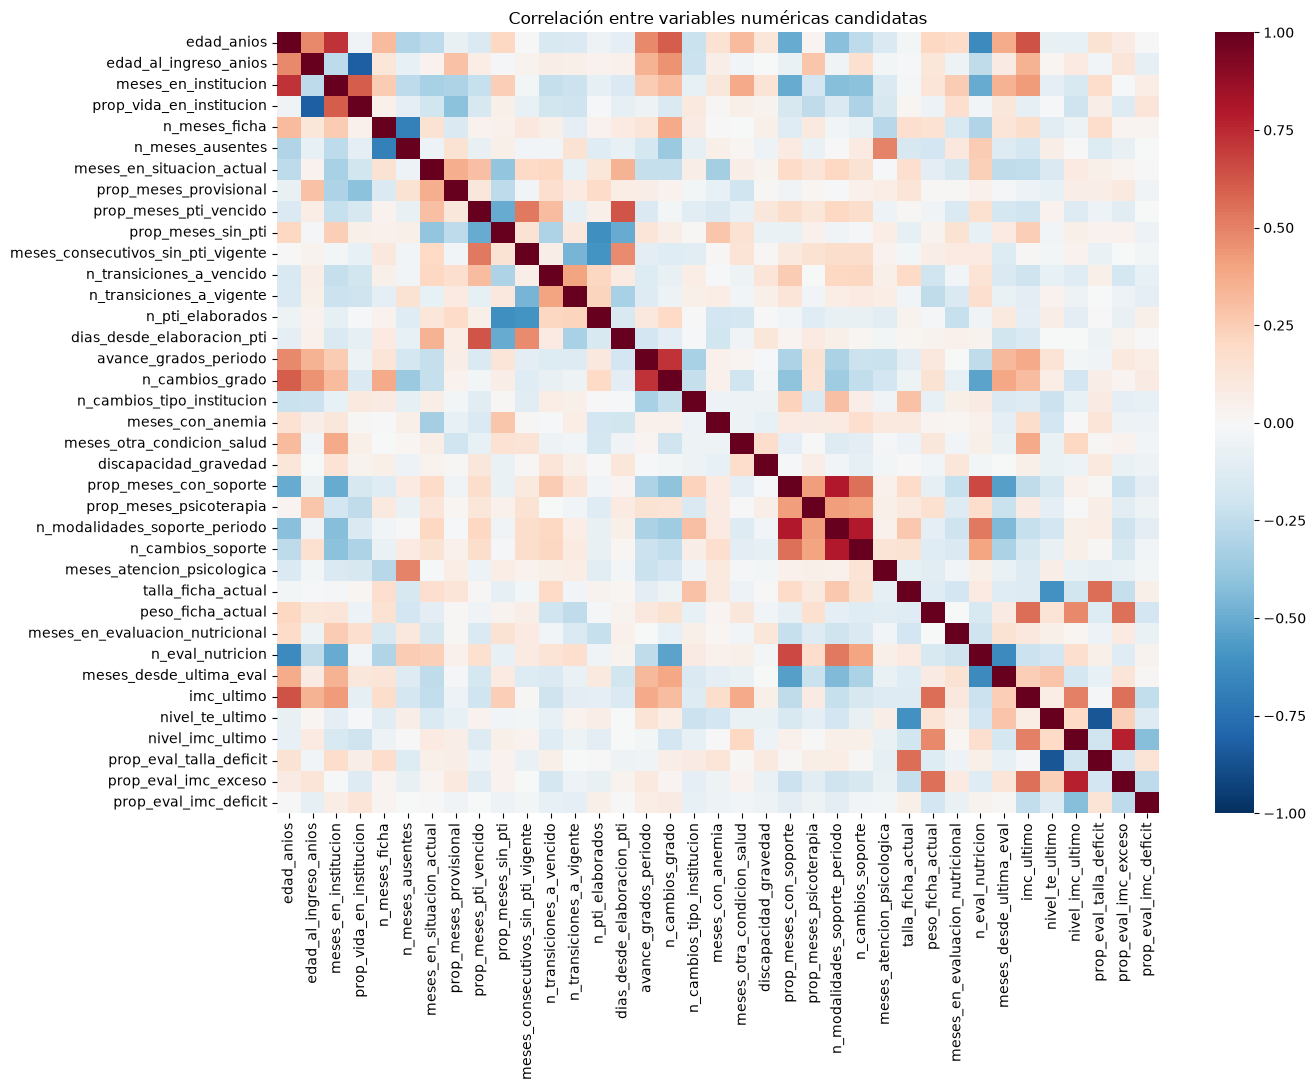

Correlación absoluta media: 0.151
Pares con |r| >= 0.30: 85 de 666


In [ ]:
plt.figure(figsize=(14, 11))
sns.heatmap(Xc.corr(), vmin=-1, vmax=1, center=0, cmap='RdBu_r', xticklabels=True, yticklabels=True)
plt.title('Correlación entre variables numéricas candidatas')
plt.tight_layout()
plt.show()

c = Xc.corr().abs().values.copy()
np.fill_diagonal(c, np.nan)
print(f'Correlación absoluta media: {np.nanmean(c):.3f}')
print(f'Pares con |r| >= 0.30: {int((c >= 0.30).sum() // 2)} de {int(c.shape[0] * (c.shape[0] - 1) / 2)}')

**Comentario 12:** la correlación absoluta media es baja, 0.15, y solo 85 de los 666 pares posibles (13 %) superan 0.30. Las relaciones fuertes se concentran en bloques con sentido: edad con meses en la institución (0.72) y con número de evaluaciones nutricionales (-0.64), proporción de meses con soporte con número de modalidades (0.80), y los indicadores de talla y de IMC entre sí (por ejemplo, nivel de IMC con persistencia de exceso: 0.78). Es una señal parcialmente favorable: hay estructura que resumir, pero la mayoría de las variables son poco relacionadas entre sí, lo que limita cuánto se puede comprimir.

# 12. Pruebas de Bartlett y KMO

In [ ]:
# Bartlett: H0 = la matriz de correlaciones es la identidad (no hay correlación entre las variables)
chi2, p_val = calculate_bartlett_sphericity(Xc)
print(f'Bartlett: chi2 = {chi2:.1f} | p-value = {p_val:.3g} | determinante de R = {np.linalg.det(np.corrcoef(Xc.T)):.3g}')

# KMO: qué parte de la varianza compartida es común (>= 0.6 aceptable, < 0.5 inaceptable)
kmo_vars, kmo_total = calculate_kmo(Xc)
print(f'KMO global = {kmo_total:.3f}')
kmo_df = pd.DataFrame({'variable': Xc.columns, 'KMO': kmo_vars}).sort_values('KMO')
kmo_df

Bartlett: chi2 = 4395.4 | p-value = 0 | determinante de R = 1.99e-18
KMO global = 0.603


,variable,KMO
12,n_transiciones_a_vigente,0.341054
19,meses_otra_condicion_salud,0.359678
17,n_cambios_tipo_institucion,0.425005
11,n_transiciones_a_vencido,0.437638
1,edad_al_ingreso_anios,0.439786
10,meses_consecutivos_sin_pti_vigente,0.444412
25,meses_atencion_psicologica,0.464967
9,prop_meses_sin_pti,0.484075
28,meses_en_evaluacion_nutricional,0.497064
33,nivel_imc_ultimo,0.510480


**Comentario 13:** la prueba de **Bartlett** rechaza que la matriz de correlaciones sea la identidad (chi² = 4 395, p < 0.001), por lo que hay correlación suficiente para aplicar PCA. Conviene leerla con cuidado: con muchas variables la prueba casi siempre se rechaza, y el determinante de la matriz es muy pequeño (2.0e-18), señal de relaciones fuertes dentro de algunos grupos. El **KMO global es 0.603**, apenas sobre el mínimo recomendado (0.6). Varias variables individuales tienen KMO menor a 0.50, es decir, no comparten varianza con las demás y distorsionarían el análisis.

In [ ]:
# Depuración iterativa: se retira, de a una, la variable con menor KMO individual hasta que todas sean >= 0.50
Xk = Xc.copy()
retiradas = []
while True:
    kv, kt = calculate_kmo(Xk)
    kv = pd.Series(kv, index=Xk.columns)
    if kv.min() >= 0.50 or Xk.shape[1] <= 5:
        break
    peor = kv.idxmin()
    retiradas.append((peor, round(kv.min(), 3)))
    Xk = Xk.drop(columns=peor)

kv, kt = calculate_kmo(Xk)
chi2k, pk = calculate_bartlett_sphericity(Xk)
print(f'Variables retiradas por KMO < 0.50 ({len(retiradas)}):')
for v, k in retiradas: print(f'  {v}: {k}')
print(f'\nVariables que quedan: {Xk.shape[1]} | KMO global = {kt:.3f} | Bartlett p = {pk:.3g}')
print(f'Observaciones por variable: {len(Xk) / Xk.shape[1]:.1f}')

Variables retiradas por KMO < 0.50 (5):
  n_transiciones_a_vigente: 0.341
  meses_otra_condicion_salud: 0.36
  edad_al_ingreso_anios: 0.44
  prop_vida_en_institucion: 0.317
  n_cambios_tipo_institucion: 0.456

Variables que quedan: 32 | KMO global = 0.671 | Bartlett p = 2.04e-232
Observaciones por variable: 3.8


**Comentario 14:** se retiran de a una las variables con KMO individual menor a 0.50: `n_transiciones_a_vigente`, `meses_otra_condicion_salud`, `edad_al_ingreso_anios`, `prop_vida_en_institucion` y `n_cambios_tipo_institucion`. Son variables de eventos poco frecuentes (transiciones, condiciones raras) o derivadas de las fechas de ingreso que ya están representadas en otras. Quedan **32 variables con KMO global 0.671** (poco, pero aceptable) y Bartlett significativo. La proporción sube a 3.8 observaciones por variable, todavía por debajo de las 5 recomendadas.

# 13. PCA: componentes y varianza explicada

In [ ]:
# Estandarización (igual que en clase: media 0 y desviación 1)
Z = (Xk - Xk.mean()) / Xk.std(ddof=0)

pca = PCA().fit(Z)
n_comp = len(pca.explained_variance_)
nombres_pc = [f'PC{i + 1}' for i in range(n_comp)]
PVE = pca.explained_variance_ratio_
PVE_acum = np.cumsum(PVE)
autovalores = pca.explained_variance_

tabla_var = pd.DataFrame({'autovalor': autovalores, 'varianza (%)': PVE * 100, 'acumulada (%)': PVE_acum * 100}, index=nombres_pc)
print('Componentes con autovalor > 1 (Kaiser):', int((autovalores > 1).sum()))
for objetivo in (0.60, 0.70, 0.80):
    print(f'Componentes para explicar {int(objetivo * 100)} % de la varianza:', int(np.argmax(PVE_acum >= objetivo) + 1))
tabla_var.head(12).round(3)

Componentes con autovalor > 1 (Kaiser): 10
Componentes para explicar 60 % de la varianza: 7
Componentes para explicar 70 % de la varianza: 9
Componentes para explicar 80 % de la varianza: 13


,autovalor,varianza (%),acumulada (%)
PC1,5.974,18.517,18.517
PC2,3.321,10.293,28.809
PC3,2.880,8.927,37.736
PC4,2.856,8.852,46.588
PC5,2.183,6.766,53.354
PC6,1.868,5.791,59.145
PC7,1.492,4.623,63.768
PC8,1.267,3.928,67.696
PC9,1.103,3.419,71.116
PC10,1.029,3.190,74.306


**Comentario 15:** se estandarizan las variables (media 0, desviación 1) y se aplica PCA como en clase, revisando la varianza explicada, la acumulada y el gráfico de sedimentación. Resultados de las primeras componentes:

| Componente | Autovalor | Varianza | Acumulada |
|---|---|---|---|
| PC1 | 5.97 | 18.5 % | 18.5 % |
| PC2 | 3.32 | 10.3 % | 28.8 % |
| PC3 | 2.88 | 8.9 % | 37.7 % |
| PC4 | 2.86 | 8.9 % | 46.6 % |
| PC5 | 2.18 | 6.8 % | 53.4 % |
| PC6 | 1.87 | 5.8 % | 59.1 % |
| PC7 | 1.49 | 4.6 % | 63.8 % |
| PC8 | 1.27 | 3.9 % | 67.7 % |
| PC9 | 1.10 | 3.4 % | 71.1 % |

**Cuántas componentes retener.** Los criterios del curso dan resultados distintos: el criterio de Kaiser (autovalor > 1) sugiere 10 componentes; para explicar el 60 % de la varianza hacen falta 7, para el 70 %, 9, y para el 80 %, 13. En el gráfico de sedimentación no hay un codo claro. Se retienen **9 componentes (71.1 % de la varianza)**, aplicando la regla del 70 %, que coincide casi con el criterio de Kaiser (10) y deja un margen razonable de información. El equipo puede ajustar este número cambiando el umbral de la celda correspondiente.

Hay que notar que la reducción de dimensiones es modesta: se pasa de 32 variables a 9 componentes, y la información está repartida en muchos ejes.

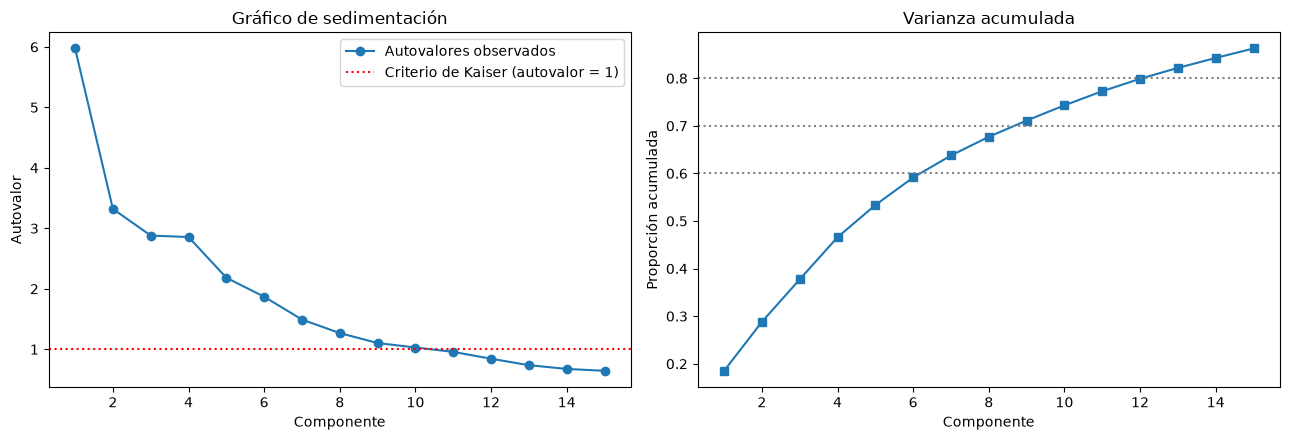

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
k = min(15, n_comp)
ax[0].plot(range(1, k + 1), autovalores[:k], marker='o', label='Autovalores observados')
ax[0].axhline(1, color='red', linestyle=':', label='Criterio de Kaiser (autovalor = 1)')
ax[0].set_title('Gráfico de sedimentación'); ax[0].set_xlabel('Componente'); ax[0].set_ylabel('Autovalor'); ax[0].legend()
ax[1].plot(range(1, k + 1), PVE_acum[:k], marker='s')
for lim in (0.6, 0.7, 0.8):
    ax[1].axhline(lim, color='gray', linestyle=':')
ax[1].set_title('Varianza acumulada'); ax[1].set_xlabel('Componente'); ax[1].set_ylabel('Proporción acumulada')
plt.tight_layout(); plt.show()

# 14. Cargas e interpretación de las componentes

In [ ]:
N_PC = int(np.argmax(PVE_acum >= 0.70) + 1)   # regla del 70 % de varianza acumulada
cargas = pd.DataFrame(pca.components_[:N_PC].T * np.sqrt(autovalores[:N_PC]), index=Xk.columns,
                      columns=nombres_pc[:N_PC])   # cargas = correlación variable-componente
print(f'Componentes que se retienen (70 % de la varianza): {N_PC} | varianza acumulada: {PVE_acum[N_PC - 1] * 100:.1f} %')

for pc in nombres_pc[:N_PC]:
    top = cargas[pc].abs().sort_values(ascending=False).head(6).index
    print(f'\n{pc} ({PVE[nombres_pc.index(pc)] * 100:.1f} % de la varianza):')
    print(cargas.loc[top, pc].round(2).to_string())

Componentes que se retienen (70 % de la varianza): 9 | varianza acumulada: 71.1 %

PC1 (18.5 % de la varianza):
edad_anios                       0.77
prop_meses_con_soporte          -0.77
n_eval_nutricion                -0.75
n_modalidades_soporte_periodo   -0.73
meses_en_institucion             0.71
meses_desde_ultima_eval          0.65

PC2 (10.3 % de la varianza):
nivel_imc_ultimo           0.70
prop_eval_talla_deficit   -0.65
prop_eval_imc_exceso       0.62
nivel_te_ultimo            0.61
talla_ficha_actual        -0.59
n_meses_ficha             -0.42

PC3 (8.9 % de la varianza):
prop_meses_sin_pti            0.74
prop_meses_pti_vencido       -0.58
dias_desde_elaboracion_pti   -0.58
meses_con_anemia              0.53
meses_en_situacion_actual    -0.49
n_pti_elaborados             -0.44

PC4 (8.9 % de la varianza):
imc_ultimo                 0.53
peso_ficha_actual          0.51
prop_meses_psicoterapia    0.50
n_meses_ausentes          -0.49
n_meses_ficha              0.49
nivel_imc_

**Comentario 16:** se interpretan las 9 componentes retenidas con sus cargas (la correlación de cada variable con la componente). Las primeras tienen una lectura clara:
- **PC1 (18.5 %) – etapa de vida frente a soporte y evaluaciones:** edad (0.77) y tiempo en la institución (0.71) se oponen a la proporción de meses con soporte (-0.77), el número de modalidades de soporte (-0.73) y el número de evaluaciones nutricionales (-0.75). Los residentes más pequeños son los más evaluados y acompañados.
- **PC2 (10.3 %) – exceso de peso frente a baja talla:** el nivel de IMC (0.70) y la persistencia del exceso (0.62) se oponen a la persistencia del déficit de talla (-0.65).
- **PC3 (8.9 %) – ausencia de PTI:** meses sin PTI (0.74) frente a PTI vencido (-0.58) y mayor antigüedad del plan (-0.58); se asocia además con más meses de anemia (0.53). Distingue a quienes nunca tuvieron PTI de quienes lo tienen vencido.
- **PC4 (8.9 %):** IMC y peso altos con psicoterapia (≈0.5) y registro de ficha completo; mezcla variables de distinta naturaleza y es difícil de nombrar.
- **PC5 (6.8 %) – sin PTI vigente de forma sostenida:** meses consecutivos sin PTI vigente (0.76) con pocas elaboraciones de PTI (-0.68).

Las componentes siguientes explican cada una menos del 6 % y son más difíciles de nombrar:
- **PC6 (5.8 %):** combina talla, psicoterapia y cambios de grado sin un tema claro.
- **PC7 (4.6 %):** meses en situación provisional (0.61), huecos de registro (0.45) y atención psicológica (0.44).
- **PC8 (3.9 %) y PC9 (3.4 %):** las dominan la gravedad de la discapacidad (0.54 y 0.44), que pocos residentes presentan, y los vencimientos del PTI.

Las dos primeras componentes recogen el eje **edad / etapa de vida** y el eje **estado nutricional**, y la tercera y la quinta, la **situación del PTI**, que coinciden con las dimensiones del objetivo del proyecto. En el gráfico de PC1-PC2 coloreado por estado del PTI no se observan grupos separados, lo que es coherente con una estructura continua y no en bloques.

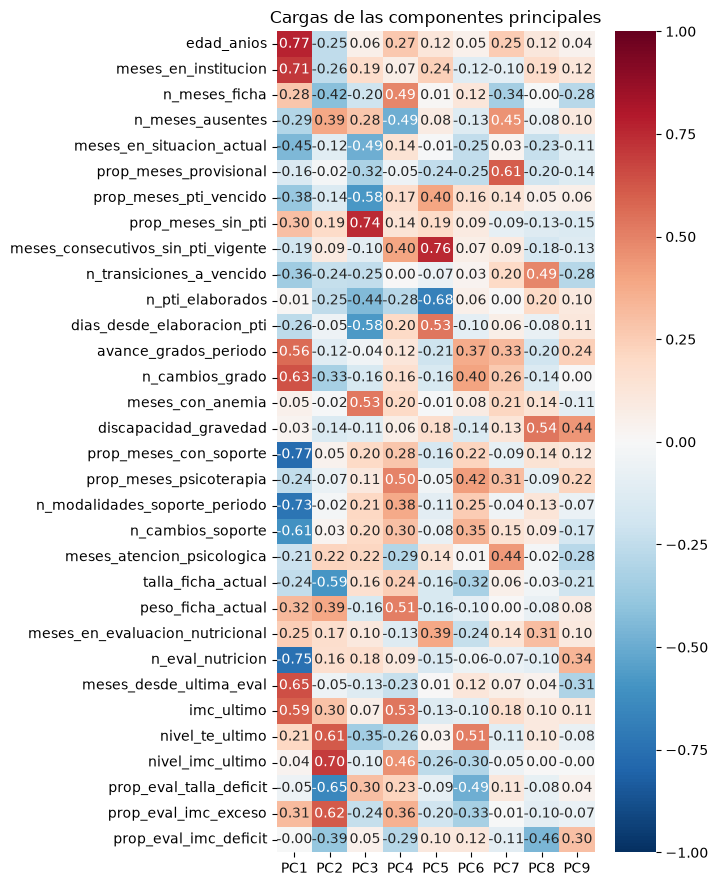

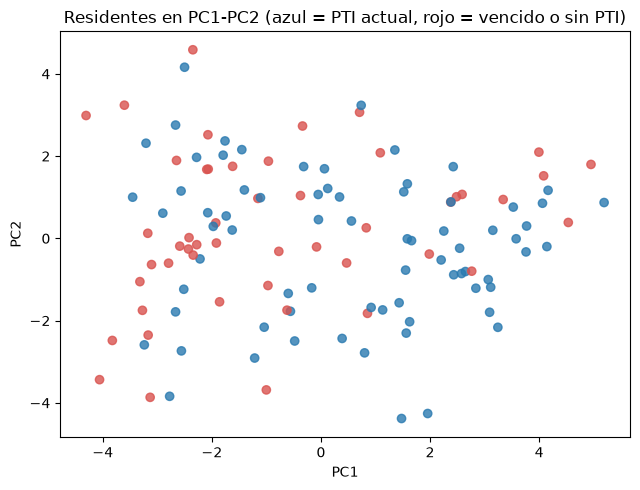

In [ ]:
plt.figure(figsize=(7, max(5, 0.28 * len(cargas))))
sns.heatmap(cargas, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=len(cargas) <= 40, fmt='.2f', yticklabels=True)
plt.title('Cargas de las componentes principales'); plt.tight_layout(); plt.show()

scores = pd.DataFrame(pca.transform(Z)[:, :N_PC], columns=nombres_pc[:N_PC], index=datos['id_persona'])
fig = plt.figure(figsize=(6.5, 5))
plt.scatter(scores['PC1'], scores['PC2'], c=(datos['pti_estado'] == 'Actual').map({True: '#2a7ab0', False: '#d9534f'}), alpha=.8)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Residentes en PC1-PC2 (azul = PTI actual, rojo = vencido o sin PTI)')
plt.tight_layout(); plt.show()

# 15. Estabilidad y variante con variables binarias

In [ ]:
# Comprobación de estabilidad: la estructura de PC1-PC3 ¿se mantiene al remuestrear los residentes?
from numpy.linalg import svd
def abs_cos(a, b): return abs(float(np.dot(a, b)))
rng = np.random.default_rng(7)
base = pca.components_[:3]
cos = []
for _ in range(200):
    idx = rng.integers(0, len(Z), len(Z))
    zb = Z.iloc[idx]
    pb = PCA(n_components=3).fit(zb)
    cos.append([abs_cos(base[i], pb.components_[i]) for i in range(3)])
est = pd.DataFrame(cos, columns=['PC1', 'PC2', 'PC3'])
print('Similitud media (coseno) del eje remuestreado con el original:')
print(est.mean().round(3).to_string())

# Variante con las variables binarias incluidas
Xb = datos[cand + [b for b in bin_f if datos[b].std() > 0]].copy().fillna(datos[cand + bin_f].median())
kb = calculate_kmo(Xb)[1]
pb_ = PCA().fit((Xb - Xb.mean()) / Xb.std(ddof=0))
print(f'\nVariante con binarias: {Xb.shape[1]} variables | KMO global = {kb:.3f} | 1.º componente = {pb_.explained_variance_ratio_[0] * 100:.1f} % | '
      f'componentes para 70 %: {int(np.argmax(np.cumsum(pb_.explained_variance_ratio_) >= 0.70) + 1)}')

Similitud media (coseno) del eje remuestreado con el original:
PC1    0.954
PC2    0.675
PC3    0.491

Variante con binarias: 49 variables | KMO global = 0.524 | 1.º componente = 14.2 % | componentes para 70 %: 12


**Comentario 17:** como complemento al procedimiento visto en clase, se remuestrearon 200 veces los residentes (bootstrap) para ver si los ejes se mantienen. La similitud con el eje original es **0.95 en PC1, 0.68 en PC2 y 0.49 en PC3**: solo la primera componente es estable; la segunda es moderada y la tercera es débil, por lo que cabe esperar que las componentes siguientes cambien aún más con otra muestra de residentes. Al agregar las 12 binarias (49 variables) el KMO global **baja a 0.52**, la primera componente cae a 14.2 % y se necesitan 12 componentes para el 70 %, por lo que incluirlas empeora la aplicabilidad.

**Conclusión sobre la aplicabilidad de PCA:**
- **Sí es técnicamente aplicable** a las variables numéricas depuradas: Bartlett es significativo, el KMO global es 0.67 y las primeras componentes se pueden interpretar.
- **Con reservas importantes:** hay solo 3.8 observaciones por variable, 11 variables necesitaron imputación para el análisis, la compresión es modesta (9 componentes para el 71 %) y únicamente PC1 es estable.
- **Recomendación:** usar el PCA de manera *exploratoria y complementaria*, por ejemplo para entender los ejes de variación o como entrada reducida de un modelo de clustering basado en distancias euclidianas como K-medias, sabiendo que más allá de PC1 los ejes son sensibles a la muestra. Para los modelos con distancia de Gower (AGNES y PAM), que aceptan variables mixtas y vacíos, conviene trabajar con las variables originales, que además conservan las categóricas y binarias que el PCA deja fuera y facilitan la interpretación de los perfiles.

# 16. Guardado de los puntajes del PCA

In [ ]:
out = pd.concat([datos[['id_persona']].reset_index(drop=True), scores.reset_index(drop=True)], axis=1)
out.to_excel(RUTA_PCA, index=False)
cargas.round(4).to_excel(RUTA_EVID / '03_cargas_pca.xlsx')
tabla_var.round(4).to_excel(RUTA_EVID / '04_varianza_pca.xlsx')
kmo_df.round(4).to_excel(RUTA_EVID / '05_kmo_por_variable.xlsx', index=False)
print('Guardado:', RUTA_PCA.name)

Guardado: Dataset_paso4_pca.xlsx


**Comentario 18:** se guardan en `Dataset_paso4_pca.xlsx` los puntajes de los 122 residentes en las 9 componentes retenidas, junto con las cargas, la varianza explicada y el KMO por variable en `Paso4_evidencias`. Este archivo no reemplaza a la matriz de variables: es una alternativa para los modelos que lo requieran, a decidir en los Pasos 5 y 6 según la comparación entre modelos.